# ML Spam Classifier Training Pipeline Using Logistics Regression
## Complete End-to-End Model Training & Evaluation

**Author:** Pride Mudondo  
**Project:** ML-Powered Contact Moderation System  
**Model:** TF-IDF + Logistic Regression  
**Date:** February 2026

---

### Pipeline Overview:
1. Loading merged dataset
2. Exploratory Data Analysis (EDA)
3. Text preprocessing
4. Feature engineering (TF-IDF)
5. Train/test split
6. Model training with hyperparameter tuning
7. Evaluation & metrics
8. Threshold optimization
9. Error analysis
10. Model export for Django


## Installation & Importation of Libraries

In [ ]:
#Installing required packages
!pip install scikit-learn pandas numpy matplotlib seaborn wordcloud joblib -q

print("All packages installed")

All packages installed


In [ ]:
#Core libraries
import pandas as pd
import numpy as np
import re
import warnings
warnings.filterwarnings('ignore')

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

#Scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

#Model persistence
import joblib
from datetime import datetime

#Google Colab file handling
from google.colab import files

#Setting visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("All libraries imported successfully")
print(f"Scikit-learn version: {__import__('sklearn').__version__}")

All libraries imported successfully
Scikit-learn version: 1.6.1


## Load Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Loading the dataset
df = pd.read_csv('/content/drive/MyDrive/spam_dataset.csv')

print(f"\n{'='*70}")
print("DATASET LOADED")
print(f"{'='*70}")
print(f"Total messages: {len(df):,}")
print(f"Columns: {list(df.columns)}")
print(f"\nFirst 3 rows:")
print(df.head(3))


DATASET LOADED
Total messages: 99,368
Columns: ['message', 'label']

First 3 rows:
                                             message label
0  want to know how to save over 60 multicolour %...  spam
1  upside of annual increases in 5 - year t - not...  spam
2  i plan to distribute at the beginning of each ...   ham


## Exploratory Data Analysis (EDA)

###Basic Dataset Info

In [ ]:
print("="*70)
print("DATASET SUMMARY")
print("="*70)

print(f"\nShape: {df.shape}")
print(f"\nData types:")
print(df.dtypes)
print(f"\nMissing values:")
print(df.isnull().sum())
print(f"\nDuplicates: {df.duplicated().sum()}")

DATASET SUMMARY

Shape: (99368, 2)

Data types:
message    object
label      object
dtype: object

Missing values:
message    0
label      0
dtype: int64

Duplicates: 264


### Class Distribution

CLASS DISTRIBUTION

label
spam    50305
ham     49063
Name: count, dtype: int64

Percentages:
label
spam    50.62495
ham     49.37505
Name: proportion, dtype: float64

Class balance ratio (spam/ham): 1.025
Class balance is reasonable for training


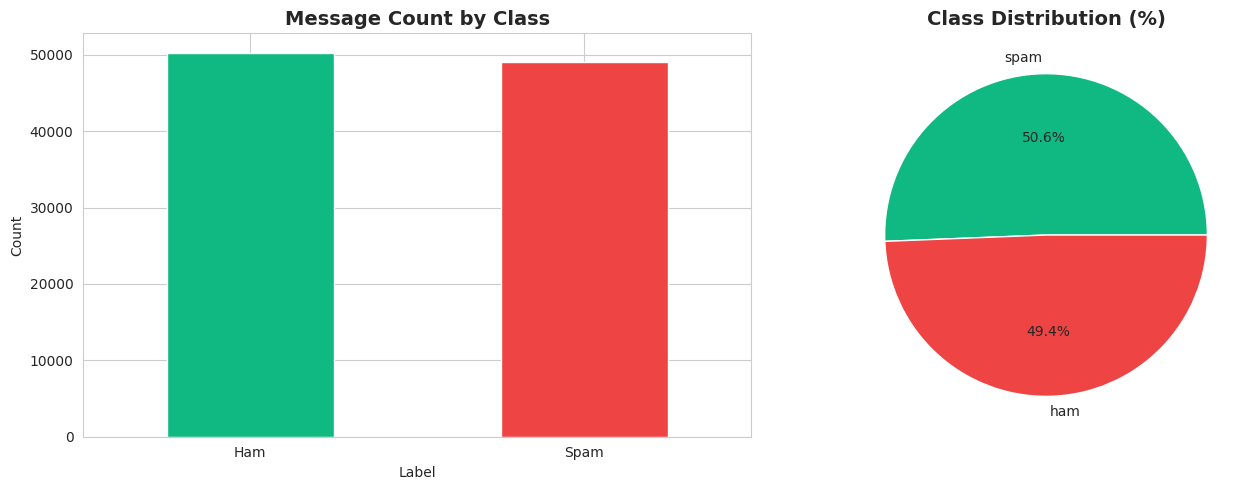

In [ ]:
#Class counts
print("="*70)
print("CLASS DISTRIBUTION")
print("="*70)

class_counts = df['label'].value_counts()
print(f"\n{class_counts}")
print(f"\nPercentages:")
print(df['label'].value_counts(normalize=True) * 100)

#Class balance ratio
spam_count = (df['label'] == 'spam').sum()
ham_count = (df['label'] == 'ham').sum()
balance_ratio = spam_count / ham_count
print(f"\nClass balance ratio (spam/ham): {balance_ratio:.3f}")

if 0.3 <= balance_ratio <= 3.0:
    print("Class balance is reasonable for training")
else:
    print("Significant class imbalance detected - will use class_weight='balanced'")

#Visualize
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

#Bar plot
class_counts.plot(kind='bar', ax=ax1, color=['#10b981', '#ef4444'])
ax1.set_title('Message Count by Class', fontsize=14, fontweight='bold')
ax1.set_xlabel('Label')
ax1.set_ylabel('Count')
ax1.set_xticklabels(['Ham', 'Spam'], rotation=0)

#Pie chart
class_counts.plot(kind='pie', ax=ax2, autopct='%1.1f%%', colors=['#10b981', '#ef4444'])
ax2.set_title('Class Distribution (%)', fontsize=14, fontweight='bold')
ax2.set_ylabel('')

plt.tight_layout()
plt.show()

###Message Length Analysis

MESSAGE LENGTH STATISTICS

Overall statistics:
count     99368.000000
mean       1496.080982
std        3889.074318
min          10.000000
25%         307.000000
50%         763.000000
75%        1701.000000
max      598705.000000
Name: message_length, dtype: float64

By class:
         count         mean          std   min    25%    50%     75%       max
label                                                                         
ham    49063.0  1860.471047  5158.505690  10.0  407.0  989.0  2001.0  598705.0
spam   50305.0  1140.687486  1915.117917  10.0  253.0  610.0  1325.0  144087.0


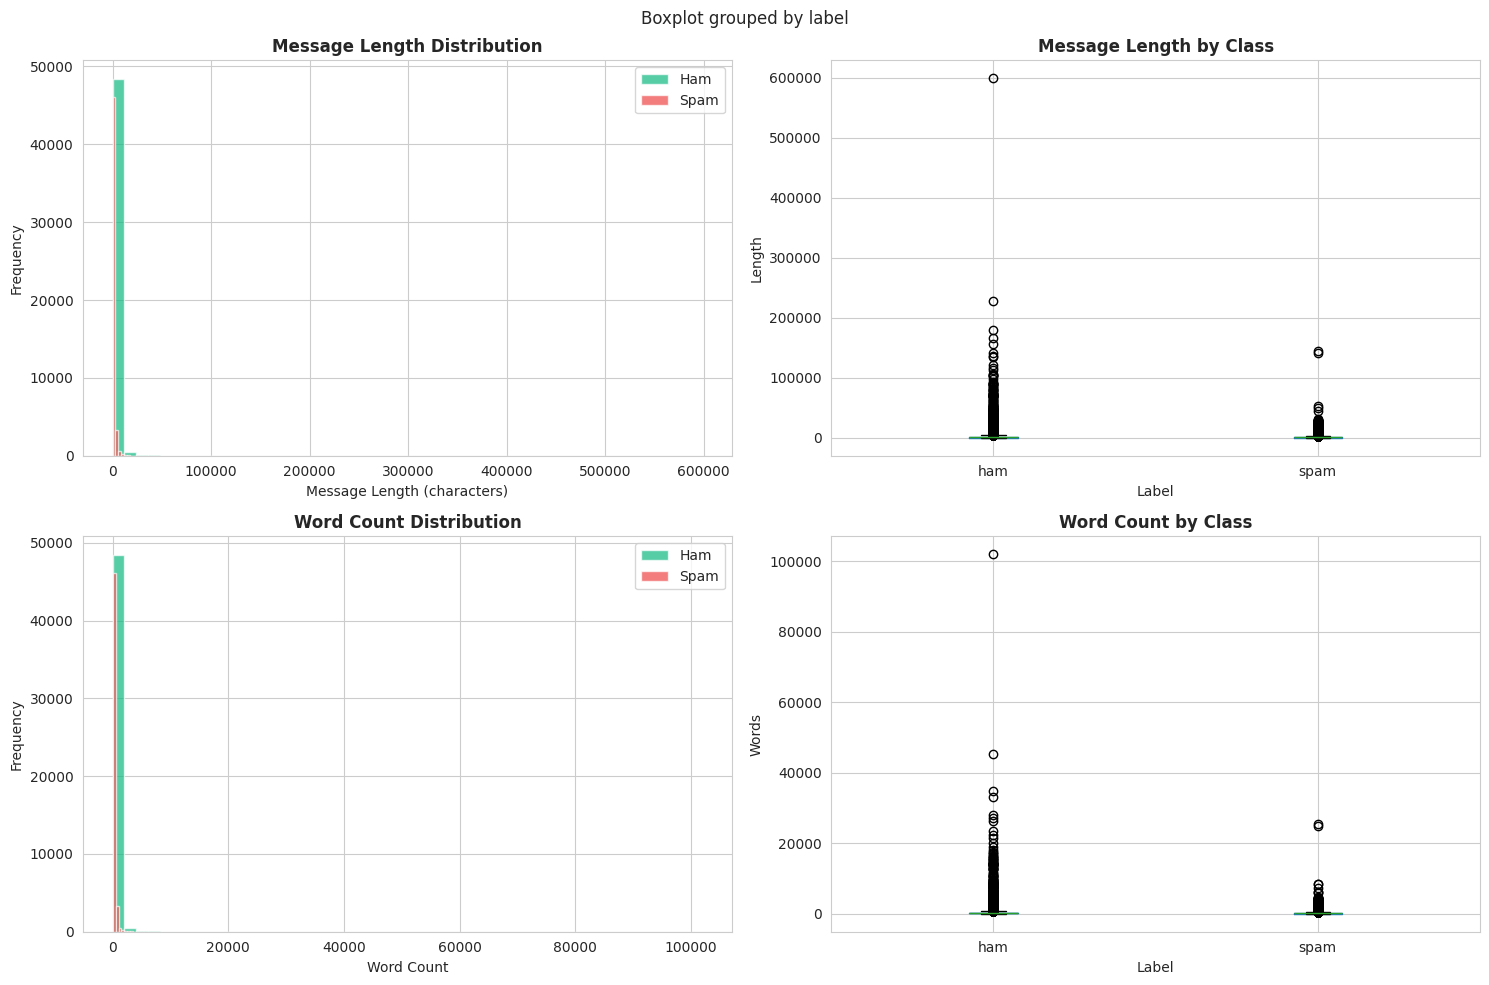

In [ ]:
#Calculate message lengths
df['message_length'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()

print("="*70)
print("MESSAGE LENGTH STATISTICS")
print("="*70)

print("\nOverall statistics:")
print(df['message_length'].describe())

print("\nBy class:")
print(df.groupby('label')['message_length'].describe())

#Visualize
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

#Character length distribution
ham_lengths = df[df['label'] == 'ham']['message_length']
spam_lengths = df[df['label'] == 'spam']['message_length']

axes[0, 0].hist(ham_lengths, bins=50, alpha=0.7, label='Ham', color='#10b981')
axes[0, 0].hist(spam_lengths, bins=50, alpha=0.7, label='Spam', color='#ef4444')
axes[0, 0].set_xlabel('Message Length (characters)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Message Length Distribution', fontweight='bold')
axes[0, 0].legend()

#Box plot
df.boxplot(column='message_length', by='label', ax=axes[0, 1])
axes[0, 1].set_title('Message Length by Class', fontweight='bold')
axes[0, 1].set_xlabel('Label')
axes[0, 1].set_ylabel('Length')

#Word count distribution
ham_words = df[df['label'] == 'ham']['word_count']
spam_words = df[df['label'] == 'spam']['word_count']

axes[1, 0].hist(ham_words, bins=50, alpha=0.7, label='Ham', color='#10b981')
axes[1, 0].hist(spam_words, bins=50, alpha=0.7, label='Spam', color='#ef4444')
axes[1, 0].set_xlabel('Word Count')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Word Count Distribution', fontweight='bold')
axes[1, 0].legend()

#Word count box plot
df.boxplot(column='word_count', by='label', ax=axes[1, 1])
axes[1, 1].set_title('Word Count by Class', fontweight='bold')
axes[1, 1].set_xlabel('Label')
axes[1, 1].set_ylabel('Words')

plt.tight_layout()
plt.show()

###Word Clouds (Most Common Words)

Generating word clouds...



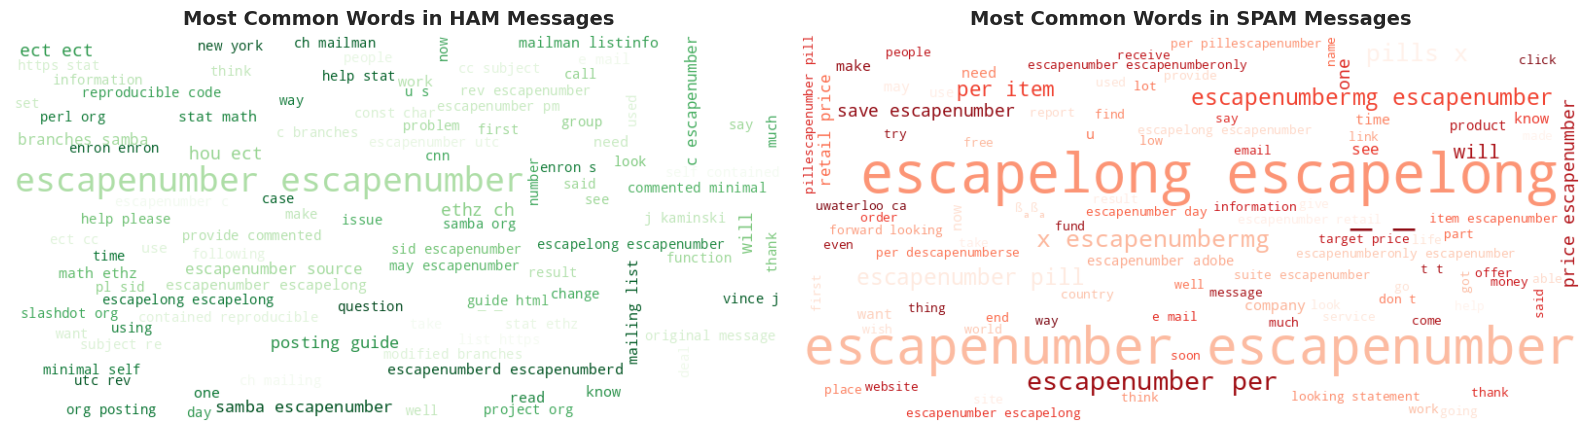

Word clouds generated successfully


In [ ]:
print("Generating word clouds...\n")

#Separating ham and spam messages
ham_text = ' '.join(df[df['label'] == 'ham']['message'])
spam_text = ' '.join(df[df['label'] == 'spam']['message'])

#Generating word clouds
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

#Ham word cloud
wordcloud_ham = WordCloud(width=800, height=400, background_color='white',
                          colormap='Greens', max_words=100).generate(ham_text)
ax1.imshow(wordcloud_ham, interpolation='bilinear')
ax1.set_title('Most Common Words in HAM Messages', fontsize=14, fontweight='bold')
ax1.axis('off')

#Spam word cloud
wordcloud_spam = WordCloud(width=800, height=400, background_color='white',
                           colormap='Reds', max_words=100).generate(spam_text)
ax2.imshow(wordcloud_spam, interpolation='bilinear')
ax2.set_title('Most Common Words in SPAM Messages', fontsize=14, fontweight='bold')
ax2.axis('off')

plt.tight_layout()
plt.show()

print("Word clouds generated successfully")

##Text Preprocessing

Clean and normalize text before feature extraction.

In [ ]:
def preprocess_text(text):
    #Lowercase
    text = text.lower()

    #Replace URLs with token
    text = re.sub(r'http\S+|www\S+|https\S+', ' URL_TOKEN ', text, flags=re.MULTILINE)

    #Replace email addresses with token
    text = re.sub(r'\S+@\S+', ' EMAIL_TOKEN ', text)

    #Replace phone numbers with token
    text = re.sub(r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b', ' PHONE_TOKEN ', text)
    text = re.sub(r'\b\d{10}\b', ' PHONE_TOKEN ', text)

    #Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

print("Preprocessing messages...\n")

#Applying preprocessing
df['message_clean'] = df['message'].apply(preprocess_text)

print("="*70)
print("PREPROCESSING EXAMPLES")
print("="*70)

for i in range(3):
    print(f"\nExample {i+1}:")
    print(f"Original:  {df.iloc[i]['message'][:100]}...")
    print(f"Cleaned:   {df.iloc[i]['message_clean'][:100]}...")

#Showing token statistics
print(f"\n{'='*70}")
print("TOKEN STATISTICS")
print(f"{'='*70}")
print(f"Messages with URLs:   {df['message_clean'].str.contains('URL_TOKEN').sum():,}")
print(f"Messages with emails: {df['message_clean'].str.contains('EMAIL_TOKEN').sum():,}")
print(f"Messages with phones: {df['message_clean'].str.contains('PHONE_TOKEN').sum():,}")

print(f"\nPreprocessing complete")

Preprocessing messages...

PREPROCESSING EXAMPLES

Example 1:
Original:  want to know how to save over 60 multicolour % on your med macrocephalous lcatlons ?
http stucco : /...
Cleaned:   want to know how to save over 60 multicolour % on your med macrocephalous lcatlons ? http stucco : /...

Example 2:
Original:  upside of annual increases in 5 - year t - note
bonus crediting over normal
treasury notes
alternati...
Cleaned:   upside of annual increases in 5 - year t - note bonus crediting over normal treasury notes alternati...

Example 3:
Original:  i plan to distribute at the beginning of each month . please let me know if you have any changes .
n...
Cleaned:   i plan to distribute at the beginning of each month . please let me know if you have any changes . n...

TOKEN STATISTICS
Messages with URLs:   7,485
Messages with emails: 123
Messages with phones: 1,480

Preprocessing complete


In [ ]:
#Outlier Removal- Outliers identified from Box Plots
print("="*70)
print("REMOVING OUTLIERS")
print("="*70)

original_count = len(df)

#Removing extremely long messages
df = df[df['message_clean'].str.len() < 5000]

removed = original_count - len(df)
print(f"\nRemoved {removed:,} messages with length >= 5000 characters")
print(f"Remaining: {len(df):,} messages")

#Verifying outliers are gone
print(f"\nNew max message length: {df['message_clean'].str.len().max()} characters")
print(f"New max word count: {df['word_count'].max()} words")

REMOVING OUTLIERS

Removed 4,263 messages with length >= 5000 characters
Remaining: 95,105 messages

New max message length: 4999 characters
New max word count: 2263 words


##Train/Test Split

Split data with stratification to maintain class balance.

In [ ]:
print("="*70)
print("TRAIN/TEST SPLIT")
print("="*70)

#Preparing features and labels
X = df['message_clean']
y = df['label']

#Splitting 80/20 with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"\nTotal dataset: {len(df):,} messages")
print(f"\nTraining set: {len(X_train):,} messages")
print(f"  - Ham:  {(y_train == 'ham').sum():,} ({(y_train == 'ham').sum()/len(y_train)*100:.1f}%)")
print(f"  - Spam: {(y_train == 'spam').sum():,} ({(y_train == 'spam').sum()/len(y_train)*100:.1f}%)")

print(f"\nTest set: {len(X_test):,} messages")
print(f"  - Ham:  {(y_test == 'ham').sum():,} ({(y_test == 'ham').sum()/len(y_test)*100:.1f}%)")
print(f"  - Spam: {(y_test == 'spam').sum():,} ({(y_test == 'spam').sum()/len(y_test)*100:.1f}%)")

print("\nSplit maintains class balance")

TRAIN/TEST SPLIT

Total dataset: 95,105 messages

Training set: 76,084 messages
  - Ham:  36,798 (48.4%)
  - Spam: 39,286 (51.6%)

Test set: 19,021 messages
  - Ham:  9,200 (48.4%)
  - Spam: 9,821 (51.6%)

Split maintains class balance


##Build ML Pipeline

Create pipeline with TF-IDF vectorization + Logistic Regression.

In [ ]:
print("="*70)
print("BUILDING ML PIPELINE")
print("="*70)

#Creating pipeline
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=10000,
        sublinear_tf=True,
        stop_words='english',
        min_df=2,
        max_df=0.95
    )),
    ('clf', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42,
        solver='lbfgs'
    ))
])

print("\nPipeline created:")
print(pipeline)

BUILDING ML PIPELINE

Pipeline created:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.95, max_features=10000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english',
                                 sublinear_tf=True)),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])


##Train Baseline Model

In [ ]:
print("="*70)
print("TRAINING BASELINE MODEL")
print("="*70)

import time
start_time = time.time()

#Training
pipeline.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"\nModel trained in {training_time:.2f} seconds")

#Predictions
y_pred = pipeline.predict(X_test)
y_pred_proba = pipeline.predict_proba(X_test)[:, 1]

print("Predictions generated")

TRAINING BASELINE MODEL

Model trained in 23.96 seconds
Predictions generated


##Model Evaluation

###Performance Metrics

In [ ]:
print("="*70)
print("MODEL PERFORMANCE METRICS")
print("="*70)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label='spam')
recall = recall_score(y_test, y_pred, pos_label='spam')
f1 = f1_score(y_test, y_pred, pos_label='spam')
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"\nAccuracy:{accuracy:.4f} ({'1' if accuracy >= 0.97 else '0'} target: >=0.97)")
print(f"Precision: {precision:.4f} ({'1' if precision >= 0.95 else '0'} target: >=0.95)")
print(f"Recall:    {recall:.4f} ({'1' if recall >= 0.93 else '0'} target: >=0.93)")
print(f"F1-score:  {f1:.4f} ({'1' if f1 >= 0.94 else '0'} target: >=0.94)")
print(f"ROC-AUC:   {roc_auc:.4f}")

# Classification report
print(f"\n{'='*70}")
print("CLASSIFICATION REPORT")
print(f"{'='*70}")
print(classification_report(y_test, y_pred, target_names=['ham', 'spam']))

MODEL PERFORMANCE METRICS

Accuracy:0.9720 (1 target: >=0.97)
Precision: 0.9714 (1 target: >=0.95)
Recall:    0.9745 (1 target: >=0.93)
F1-score:  0.9730 (1 target: >=0.94)
ROC-AUC:   0.9967

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         ham       0.97      0.97      0.97      9200
        spam       0.97      0.97      0.97      9821

    accuracy                           0.97     19021
   macro avg       0.97      0.97      0.97     19021
weighted avg       0.97      0.97      0.97     19021



###Confusion Matrix

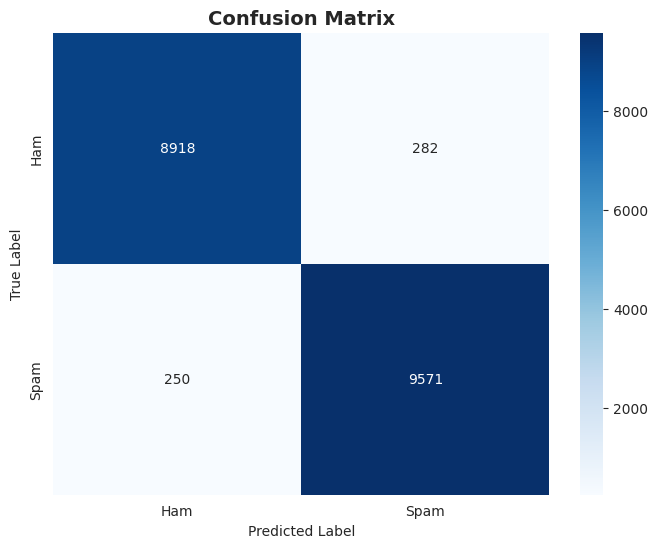


True Negatives (correctly identified ham):  8,918
False Positives (ham wrongly marked spam): 282 Need to minimize these!
False Negatives (spam wrongly marked ham):  250
True Positives (correctly identified spam): 9,571


In [ ]:
#Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=['ham', 'spam'])

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'],
            yticklabels=['Ham', 'Spam'])
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

#Breakdown
tn, fp, fn, tp = cm.ravel()
print(f"\nTrue Negatives (correctly identified ham):  {tn:,}")
print(f"False Positives (ham wrongly marked spam): {fp:,} Need to minimize these!")
print(f"False Negatives (spam wrongly marked ham):  {fn:,}")
print(f"True Positives (correctly identified spam): {tp:,}")

###ROC Curve

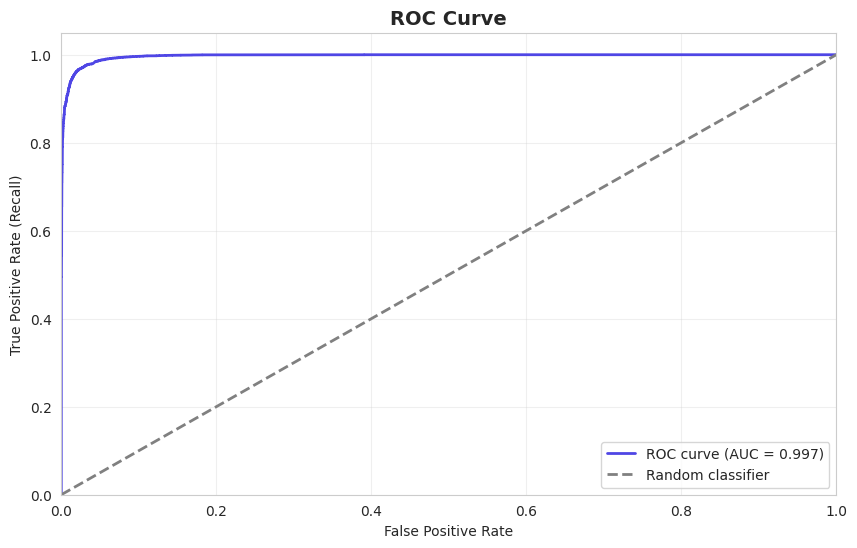

In [ ]:
#ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba, pos_label='spam')

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='#4f46e5', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve', fontsize=14, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

##Cross-Validation

Verify model generalizes well across different data splits.

In [ ]:
print("="*70)
print("5-FOLD CROSS-VALIDATION")
print("="*70)

cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='accuracy')

print(f"\nFold scores: {[f'{s:.4f}' for s in cv_scores]}")
print(f"\nMean accuracy: {cv_scores.mean():.4f} ({'1' if cv_scores.mean() >= 0.96 else '0'} target: >= 0.96)")
print(f"Std deviation: {cv_scores.std():.4f}")

if cv_scores.std() < 0.01:
    print("\nLow variance - model is stable across folds")
else:
    print("\nHigh variance - model performance varies across folds")

5-FOLD CROSS-VALIDATION

Fold scores: ['0.9721', '0.9677', '0.9721', '0.9715', '0.9706']

Mean accuracy: 0.9708 (1 target: >= 0.96)
Std deviation: 0.0017

Low variance - model is stable across folds


##Hyperparameter Tuning

Fine-tune if baseline doesn't meet targets.

In [ ]:
if accuracy >= 0.97 and precision >= 0.95 and recall >= 0.93:
    print("Baseline model already meets all performance targets!")
    print("Skipping hyperparameter tuning.")
    best_pipeline = pipeline
else:
    print("Tuning hyperparameters...\n")

    param_grid = {
        'tfidf__max_features': [8000, 10000, 12000],
        'tfidf__ngram_range': [(1, 2), (1, 3)],
        'clf__C': [0.1, 1.0, 10.0],
        'clf__class_weight': ['balanced', None]
    }

    grid_search = GridSearchCV(
        pipeline, param_grid,
        cv=3, scoring='f1',
        n_jobs=-1, verbose=1
    )

    grid_search.fit(X_train, y_train)

    print(f"\nBest parameters: {grid_search.best_params_}")
    print(f"Best F1-score: {grid_search.best_score_:.4f}")

    best_pipeline = grid_search.best_estimator_

Baseline model already meets all performance targets!
Skipping hyperparameter tuning.


##Threshold Optimization

Find optimal classification threshold (default is 0.50).

THRESHOLD OPTIMIZATION

Threshold Analysis:
 threshold  precision   recall       f1
      0.70   0.988197 0.937786 0.962332
      0.75   0.990590 0.921800 0.954958
      0.80   0.993025 0.898788 0.943560
      0.85   0.995683 0.868954 0.928012

RECOMMENDED THRESHOLD: 0.70
Precision: 0.9882
Recall:    0.9378
F1-score:  0.9623


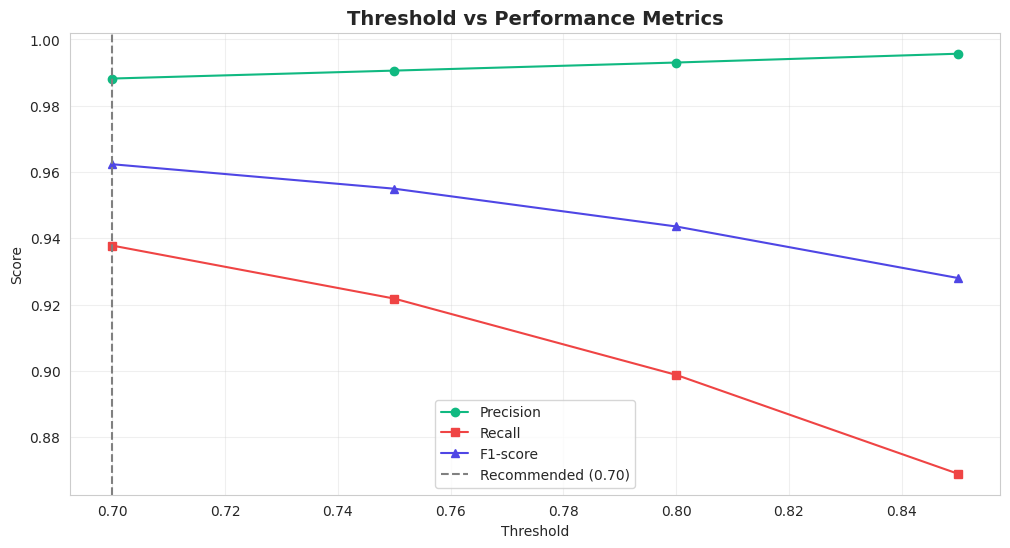

In [ ]:
print("="*70)
print("THRESHOLD OPTIMIZATION")
print("="*70)

#Testing different thresholds
thresholds_to_test = np.arange(0.7, 0.85, 0.05)
results = []

for threshold in thresholds_to_test:
    y_pred_thresh = (y_pred_proba >= threshold).astype(int)
    y_pred_thresh = ['spam' if p == 1 else 'ham' for p in y_pred_thresh]

    prec = precision_score(y_test, y_pred_thresh, pos_label='spam')
    rec = recall_score(y_test, y_pred_thresh, pos_label='spam')
    f1_thresh = f1_score(y_test, y_pred_thresh, pos_label='spam')

    results.append({
        'threshold': threshold,
        'precision': prec,
        'recall': rec,
        'f1': f1_thresh
    })

results_df = pd.DataFrame(results)
print("\nThreshold Analysis:")
print(results_df.to_string(index=False))

recommended = results_df[results_df['precision'] >= 0.95].nlargest(1, 'f1')
recommended_threshold = recommended['threshold'].values[0]

print(f"\n{'='*70}")
print(f"RECOMMENDED THRESHOLD: {recommended_threshold:.2f}")
print(f"{'='*70}")
print(f"Precision: {recommended['precision'].values[0]:.4f}")
print(f"Recall:    {recommended['recall'].values[0]:.4f}")
print(f"F1-score:  {recommended['f1'].values[0]:.4f}")

#Visualization
plt.figure(figsize=(12, 6))
plt.plot(results_df['threshold'], results_df['precision'], marker='o', label='Precision', color='#10b981')
plt.plot(results_df['threshold'], results_df['recall'], marker='s', label='Recall', color='#ef4444')
plt.plot(results_df['threshold'], results_df['f1'], marker='^', label='F1-score', color='#4f46e5')
plt.axvline(recommended_threshold, color='gray', linestyle='--', label=f'Recommended ({recommended_threshold:.2f})')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Threshold vs Performance Metrics', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##Error Analysis

Examining misclassified messages.

In [ ]:
print("="*70)
print("ERROR ANALYSIS")
print("="*70)

#Finding misclassifications
errors_df = pd.DataFrame({
    'message': X_test,
    'true_label': y_test,
    'predicted_label': y_pred,
    'spam_probability': y_pred_proba
}).reset_index(drop=True)

errors_df['correct'] = errors_df['true_label'] == errors_df['predicted_label']
misclassified = errors_df[~errors_df['correct']]

print(f"\nTotal misclassified: {len(misclassified):,}")

#False Positives
false_positives = misclassified[misclassified['true_label'] == 'ham']
print(f"\nFalse Positives (ham - spam): {len(false_positives)}")
if len(false_positives) > 0:
    print("\nTop 5 False Positives:")
    for idx, row in false_positives.head(5).iterrows():
        print(f"  [{row['spam_probability']:.3f}] {row['message'][:80]}...")

#False Negatives
false_negatives = misclassified[misclassified['true_label'] == 'spam']
print(f"\nFalse Negatives (spam - ham): {len(false_negatives)}")
if len(false_negatives) > 0:
    print("\nTop 5 False Negatives:")
    for idx, row in false_negatives.head(5).iterrows():
        print(f"  [{row['spam_probability']:.3f}] {row['message'][:80]}...")

ERROR ANALYSIS

Total misclassified: 532

False Positives (ham - spam): 282

Top 5 False Positives:
  [0.857] what he said is not the matter. my mind saying some other matter is there....
  [0.592] y she dun believe leh? i tot i told her it's true already. i thk she muz c us to...
  [0.632] ola would get back to you maybe not today but i ve told him you can be his direc...
  [0.745] (that said can you text him one more time?)...
  [0.853] bammelyoungfamilies - - - - - - - - - - - - - - - - - - - - - - - - - - - listbo...

False Negatives (spam - ham): 250

Top 5 False Negatives:
  [0.441] accost attrition cull backspace barclay damask citroen dispensate colonel cheate...
  [0.424] good evening . hngu che ' shi...
  [0.364] blur phones pdas phones bluetooth magnets magnets stick metals shouldnt depend r...
  [0.213] see a list of commands you can use this utility to reset the irq o makes symlink...
  [0.342] since it was created many programmer packages and toolkits have been developed 

##Feature Importance

Most important words for spam classification.

In [ ]:
print("="*70)
print("TOP SPAM INDICATORS")
print("="*70)

#Getting feature names and coefficients
feature_names = best_pipeline.named_steps['tfidf'].get_feature_names_out()
coefficients = best_pipeline.named_steps['clf'].coef_[0]

#Sorting by coefficient
top_spam_idx = coefficients.argsort()[-20:][::-1]
top_ham_idx = coefficients.argsort()[:20]

print("\nTop 20 SPAM indicators:")
for i, idx in enumerate(top_spam_idx, 1):
    print(f"  {i:2d}. {feature_names[idx]:20s} (coef: {coefficients[idx]:6.3f})")

print("\nTop 20 HAM indicators:")
for i, idx in enumerate(top_ham_idx, 1):
    print(f"  {i:2d}. {feature_names[idx]:20s} (coef: {coefficients[idx]:6.3f})")

TOP SPAM INDICATORS

Top 20 SPAM indicators:
   1. http                 (coef:  6.497)
   2. url_token            (coef:  5.725)
   3. mobile               (coef:  5.588)
   4. escapenumber         (coef:  5.240)
   5. info                 (coef:  5.055)
   6. hk                   (coef:  4.798)
   7. embody               (coef:  4.638)
   8. claim                (coef:  4.572)
   9. men                  (coef:  4.213)
  10. 150p                 (coef:  4.169)
  11. 2005                 (coef:  4.165)
  12. adf                  (coef:  4.083)
  13. 2004                 (coef:  4.005)
  14. remove               (coef:  3.749)
  15. quality              (coef:  3.635)
  16. site                 (coef:  3.615)
  17. phone_token          (coef:  3.516)
  18. exist                (coef:  3.499)
  19. stop                 (coef:  3.397)
  20. click                (coef:  3.325)

Top 20 HAM indicators:
   1. enron                (coef: -10.684)
   2. wrote                (coef: -8.527)
   3. 

##Save Model for Django

Export trained model with metadata.

In [ ]:
print("="*70)
print("SAVING MODEL")
print("="*70)

#Model metadata
model_metadata = {
    'version': 'v1.0',
    'trained_at': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'training_samples': len(X_train),
    'test_samples': len(X_test),
    'accuracy': float(accuracy),
    'precision': float(precision),
    'recall': float(recall),
    'f1_score': float(f1),
    'roc_auc': float(roc_auc),
    'recommended_threshold': float(recommended_threshold),
    'cv_mean_accuracy': float(cv_scores.mean()),
    'cv_std': float(cv_scores.std())
}

#Saving pipeline
model_filename = 'spam_classifier_v1.joblib'
joblib.dump(best_pipeline, model_filename)
print(f"\nModel saved: {model_filename}")

# Save metadata
metadata_filename = 'model_metadata_v1.json'
import json
with open(metadata_filename, 'w') as f:
    json.dump(model_metadata, f, indent=2)
print(f"Metadata saved: {metadata_filename}")

#Displaying metadata
print(f"\n{'='*70}")
print("MODEL METADATA")
print(f"{'='*70}")
for key, value in model_metadata.items():
    print(f"{key:25s}: {value}")

#Downloading files
print(f"\n{'='*70}")
print("Downloading files...")
print(f"{'='*70}")
files.download(model_filename)
files.download(metadata_filename)
print("\nDownload complete!")

SAVING MODEL

Model saved: spam_classifier_v1.joblib
Metadata saved: model_metadata_v1.json

MODEL METADATA
version                  : v1.0
trained_at               : 2026-03-10 15:45:24
training_samples         : 76084
test_samples             : 19021
accuracy                 : 0.9720309132011987
precision                : 0.9713792753476098
recall                   : 0.974544343753182
f1_score                 : 0.9729592355392904
roc_auc                  : 0.9967344930782751
recommended_threshold    : 0.7
cv_mean_accuracy         : 0.9708217207469068
cv_std                   : 0.0016713516950429533



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Download complete!


##Test Model Inference

Verifying the saved model works correctly.

In [ ]:
print("="*70)
print("TESTING MODEL INFERENCE")
print("="*70)

# Load saved model
loaded_pipeline = joblib.load(model_filename)
print("\nModel loaded successfully")

# Test messages
test_messages = [
    "300 points in just 3 days. So many ways to earn. You’re already racking up Microsoft Rewards points when you play games or shop the Microsoft Store for games and add-ons. Plus, every Bing search adds even more.Limited-time bonus: Search on Bing 3 times in 7 days and score a bonus 300 Microsoft Rewards points. Easy win."
]

print("\nTest predictions:\n")
for msg in test_messages:
    # Preprocess
    msg_clean = preprocess_text(msg)

    # Predict
    spam_prob = loaded_pipeline.predict_proba([msg_clean])[0][1]
    prediction = 'SPAM' if spam_prob >= recommended_threshold else 'HAM'

    prediction_signal = '0' if prediction == 'SPAM' else '1'
    print(f"{prediction_signal} [{prediction:4s}] ({spam_prob:.3f}) {msg[:60]}...")

print("\nInference test complete")

TESTING MODEL INFERENCE

Model loaded successfully

Test predictions:

0 [SPAM] (0.961) 300 points in just 3 days. So many ways to earn. You’re alre...

Inference test complete
